# E-Waste Plastic Identification and Reuse System
## train.ipynb — Stage 0 (Material Sorter) & Stage 1 (Item Classifier)

**Run this notebook on Google Colab with a GPU.**  
When done, download `reform_models.zip` and extract it to `models\` on your machine.

### Setup steps
1. `File → Upload notebook` — upload this file
2. `Runtime → Change runtime type → T4 GPU`
3. Upload your dataset zip **or** connect Google Drive (see Cell 2)
4. Run all cells top-to-bottom
5. Download `reform_models.zip` from Cell 14

### Dataset folder structure expected
```
reform_data/
  stage0/
    train/  plastic/  metal/  PCB/  glass_screen/  cable_wire/  battery/  unknown/
    val/    (same 7 sub-folders)
    test/   (same 7 sub-folders — do NOT augment or touch until evaluation.ipynb)
  stage1/
    train/  keyboard/  mouse/  charger_casing/  printer_casing/  tv_panel/  remote/  other_plastic/  unknown/
    val/    (same 8 sub-folders)
    test/   (same 8 sub-folders)
```

> **Design note:** A photo alone cannot reliably identify polymer type — ABS, PC, and HIPS look nearly identical visually. Stage 0 classifies *material category*; Stage 1 classifies *item type*. Polymer identification uses the resin-code OCR in Stage 2 (`app.py`).

# Local machine — no Colab install needed (already installed in 'reform' conda env)
# Only import libraries — all dependencies installed via requirements.txt

import os, json, time, random, zipfile
from pathlib import Path

import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0, MobileNetV3Large
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mnv2_preprocess

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

print(f"TensorFlow: {tf.__version__}")
print(f"GPU devices: {tf.config.list_physical_devices('GPU')}")

In [1]:
# Colab already has TensorFlow, OpenCV, scikit-learn, matplotlib — just pin versions.
# easyocr and thefuzz are not pre-installed.
!pip install -q "tensorflow==2.15.0" easyocr "thefuzz[speedup]"

import os, json, time, random, zipfile
from pathlib import Path

import numpy as np
import cv2                   # loads BGR — always convert to RGB before display
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0, MobileNetV3Large
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mnv2_preprocess
# EfficientNetB0 and MobileNetV3Large include their own normalisation inside
# the model graph — pass raw [0, 255] pixels, not scaled values.

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

print(f"TensorFlow : {tf.__version__}")
print(f"GPU devices: {tf.config.list_physical_devices('GPU')}")
# If GPU devices is empty, go to Runtime → Change runtime type → T4 GPU


TensorFlow : 2.15.0
GPU devices: []


# ── Option A: Local machine ──────────────────────────────────────────────────
# Path to your dataset folder locally
DATA_ROOT = Path(r'data')

STAGE0_ROOT = DATA_ROOT / 'stage0'
STAGE1_ROOT = DATA_ROOT / 'stage1'
OUTPUT_DIR  = Path('models')
OUTPUT_DIR.mkdir(exist_ok=True)

# Verify paths
for p in [STAGE0_ROOT, STAGE1_ROOT]:
    if not p.exists():
        raise FileNotFoundError(
            f"{p} not found.\nMake sure your data is in G:\\clg\\ReForm\\data\\"
        )

# Count images per split / class
def count_images(root):
    exts = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
    for split in ['train', 'val', 'test']:
        sp = root / split
        if not sp.exists():
            print(f"  [{split}] not found")
            continue
        classes = sorted(d.name for d in sp.iterdir() if d.is_dir())
        counts  = {c: len([f for f in (sp/c).iterdir() if f.suffix.lower() in exts]) for c in classes}
        print(f"  [{split}] total={sum(counts.values())}  " +
              "  ".join(f"{c}:{n}" for c, n in counts.items()))

print("Stage 0:"); count_images(STAGE0_ROOT)
print("Stage 1:"); count_images(STAGE1_ROOT)

In [2]:
# ── Local paths ────────────────────────────────────────────────────────────────
DATA_ROOT   = Path(r"data")
STAGE0_ROOT = DATA_ROOT / "stage0"
STAGE1_ROOT = DATA_ROOT / "stage1"
OUTPUT_DIR  = Path("models")
OUTPUT_DIR.mkdir(exist_ok=True)

# Variables used by Cell 3 / Cell 8 (explicitly defined here for scope safety)
IMG_SIZE       = 224
BATCH_SIZE     = 32
EPOCHS_HEAD    = 15
EPOCHS_FINE    = 10
FINE_TUNE_AT   = -30
LR_HEAD        = 1e-3
LR_FINE        = 1e-5
DROPOUT        = 0.4
CONF_THRESHOLD = 0.70
SEED           = 42
STAGE0_CLASSES = ["plastic", "metal", "PCB", "glass_screen", "battery", "unknown"]
STAGE1_CLASSES = ["keyboard", "mouse", "printer_casing", "tv_panel", "remote", "other_plastic", "unknown"]

# Verify data exists
for p in [STAGE0_ROOT, STAGE1_ROOT]:
    if not p.exists():
        raise FileNotFoundError(
            f"Dataset folder not found: {p}\n"
            f"Make sure G:\\clg\\ReForm\\data\\stage0/ and data\\stage1/ exist."
        )

# Count images per split / class
exfile = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images(root):
    for split in ["train", "val", "test"]:
        sp = root / split
        if not sp.exists():
            print(f"  [{split}] MISSING")
            continue
        classes = sorted(d.name for d in sp.iterdir() if d.is_dir())
        counts  = {c: len([f for f in (sp / c).iterdir() if f.suffix.lower() in exfile]) for c in classes}
        print(f"  [{split}] total={sum(counts.values())}  " +
              "  ".join(f"{c}:{n}" for c, n in counts.items()))

print("Stage 0 data:"); count_images(STAGE0_ROOT)
print("\nStage 1 data:"); count_images(STAGE1_ROOT)

Stage 0 data:
  [train] total=6751  PCB:602  battery:548  glass_screen:503  metal:553  plastic:3146  unknown:1399
  [val] total=1814  PCB:145  battery:127  glass_screen:117  metal:144  plastic:899  unknown:382
  [test] total=1078  PCB:103  battery:83  glass_screen:80  metal:102  plastic:494  unknown:216

Stage 1 data:
  [train] total=5351  keyboard:311  mouse:331  other_plastic:1219  printer_casing:315  remote:298  tv_panel:322  unknown:2555
  [val] total=1514  keyboard:108  mouse:80  other_plastic:368  printer_casing:88  remote:92  tv_panel:88  unknown:690
  [test] total=778  keyboard:40  mouse:38  other_plastic:189  printer_casing:47  remote:61  tv_panel:44  unknown:359


## Cell 3 — Configuration

Edit class names here to match your folder names exactly.

In [3]:
# ── Local paths ────────────────────────────────────────────────────────────────
DATA_ROOT   = Path(r"data")
STAGE0_ROOT = DATA_ROOT / "stage0"
STAGE1_ROOT = DATA_ROOT / "stage1"
OUTPUT_DIR  = Path("models")
OUTPUT_DIR.mkdir(exist_ok=True)

# Variables used by Cell 3 / Cell 8 (explicitly defined here for scope safety)
IMG_SIZE       = 224
BATCH_SIZE     = 32
EPOCHS_HEAD    = 15
EPOCHS_FINE    = 10
FINE_TUNE_AT   = -30
LR_HEAD        = 1e-3
LR_FINE        = 1e-5
DROPOUT        = 0.4
CONF_THRESHOLD = 0.70
SEED           = 42
STAGE0_CLASSES = ["plastic", "metal", "PCB", "glass_screen", "battery", "unknown"]
STAGE1_CLASSES = ["keyboard", "mouse", "printer_casing", "tv_panel", "remote", "other_plastic", "unknown"]

# Verify data exists
for p in [STAGE0_ROOT, STAGE1_ROOT]:
    if not p.exists():
        raise FileNotFoundError(
            f"Dataset folder not found: {p}\n"
            f"Make sure G:\\clg\\ReForm\\data\\stage0/ and data\\stage1/ exist."
        )

# Count images per split / class
exfile = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images(root):
    for split in ["train", "val", "test"]:
        sp = root / split
        if not sp.exists():
            print(f"  [{split}] MISSING")
            continue
        classes = sorted(d.name for d in sp.iterdir() if d.is_dir())
        counts  = {c: len([f for f in (sp / c).iterdir() if f.suffix.lower() in exfile]) for c in classes}
        print(f"  [{split}] total={sum(counts.values())}  " +
              "  ".join(f"{c}:{n}" for c, n in counts.items()))

print("Stage 0 data:"); count_images(STAGE0_ROOT)
print("\nStage 1 data:"); count_images(STAGE1_ROOT)

Stage 0 data:
  [train] total=6751  PCB:602  battery:548  glass_screen:503  metal:553  plastic:3146  unknown:1399
  [val] total=1814  PCB:145  battery:127  glass_screen:117  metal:144  plastic:899  unknown:382
  [test] total=1078  PCB:103  battery:83  glass_screen:80  metal:102  plastic:494  unknown:216

Stage 1 data:
  [train] total=5351  keyboard:311  mouse:331  other_plastic:1219  printer_casing:315  remote:298  tv_panel:322  unknown:2555
  [val] total=1514  keyboard:108  mouse:80  other_plastic:368  printer_casing:88  remote:92  tv_panel:88  unknown:690
  [test] total=778  keyboard:40  mouse:38  other_plastic:189  printer_casing:47  remote:61  tv_panel:44  unknown:359


## Cell 4 — Data generators and class weights

In [4]:
def make_generators(stage_root, model_name='mobilenetv2'):
    """
    Build train/val/test generators for a stage folder.

    Augmentation only on train — val/test use the same preprocessing
    but no random transforms so metrics are meaningful.

    preprocessing:
      MobileNetV2   → mnv2_preprocess (scales to [-1, 1])
      EfficientNetB0 / MobileNetV3Large → None (normalisation is built into the model)
    """
    pre = mnv2_preprocess if model_name == 'mobilenetv2' else None

    train_gen = ImageDataGenerator(
        preprocessing_function=pre,
        rotation_range=20,
        horizontal_flip=True,
        brightness_range=[0.7, 1.3],
        zoom_range=0.15,
        width_shift_range=0.1,
        height_shift_range=0.1,
        fill_mode='nearest',
    ).flow_from_directory(
        str(stage_root / 'train'),
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=True,
        seed=SEED,
    )

    eval_dg = ImageDataGenerator(preprocessing_function=pre)
    val_gen  = eval_dg.flow_from_directory(str(stage_root / 'val'),  target_size=(IMG_SIZE,IMG_SIZE), batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False, seed=SEED)
    test_gen = eval_dg.flow_from_directory(str(stage_root / 'test'), target_size=(IMG_SIZE,IMG_SIZE), batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False, seed=SEED)

    print(f"  [{model_name}] train={train_gen.n}  val={val_gen.n}  test={test_gen.n}")
    print(f"   class indices: {train_gen.class_indices}")
    return train_gen, val_gen, test_gen, list(train_gen.class_indices.keys())


def get_class_weights(gen):
    """Balanced class weights so rare classes aren't ignored during training."""
    w = compute_class_weight('balanced', classes=np.unique(gen.classes), y=gen.classes)
    cw = dict(enumerate(w))
    print(f"   weights: { {k: round(v,2) for k,v in cw.items()} }")
    return cw


print("Stage 0:")
s0_train, s0_val, s0_test, s0_classes = make_generators(STAGE0_ROOT)
s0_cw = get_class_weights(s0_train)

print("\nStage 1:")
s1_train, s1_val, s1_test, s1_classes = make_generators(STAGE1_ROOT)
s1_cw = get_class_weights(s1_train)

Stage 0:
Found 6751 images belonging to 6 classes.
Found 1814 images belonging to 6 classes.
Found 1078 images belonging to 6 classes.
  [mobilenetv2] train=6751  val=1814  test=1078
   class indices: {'PCB': 0, 'battery': 1, 'glass_screen': 2, 'metal': 3, 'plastic': 4, 'unknown': 5}
   weights: {0: 1.87, 1: 2.05, 2: 2.24, 3: 2.03, 4: 0.36, 5: 0.8}

Stage 1:
Found 5351 images belonging to 7 classes.
Found 1514 images belonging to 7 classes.
Found 778 images belonging to 7 classes.
  [mobilenetv2] train=5351  val=1514  test=778
   class indices: {'keyboard': 0, 'mouse': 1, 'other_plastic': 2, 'printer_casing': 3, 'remote': 4, 'tv_panel': 5, 'unknown': 6}
   weights: {0: 2.46, 1: 2.31, 2: 0.63, 3: 2.43, 4: 2.57, 5: 2.37, 6: 0.3}


## Cell 5 — Visualise a sample batch

Always do this before training — catches wrong paths, BGR/RGB swaps, or mislabelled images.

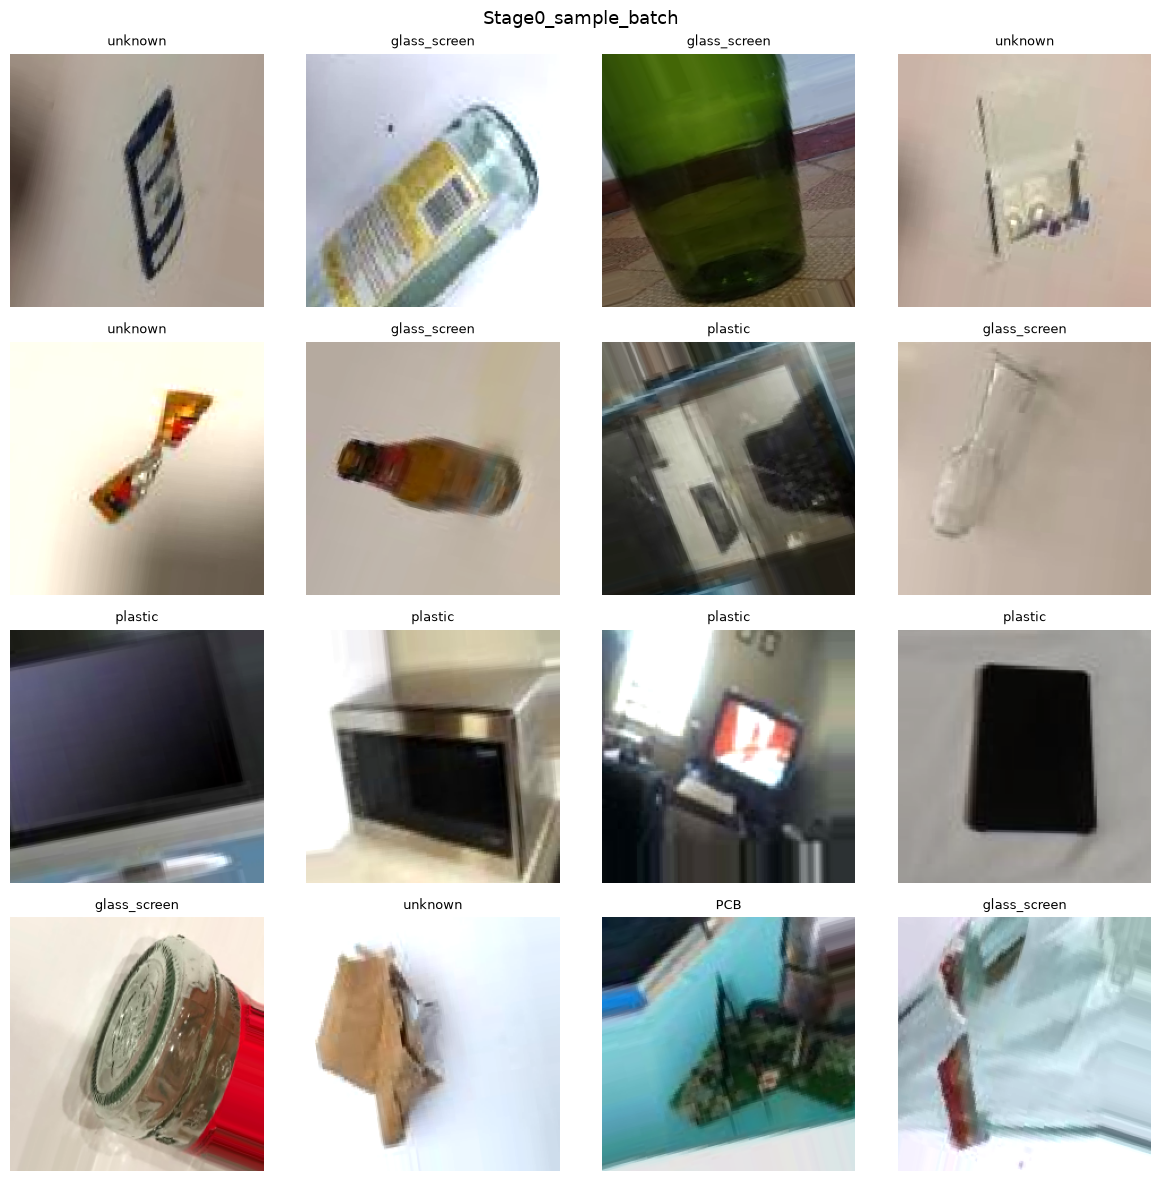

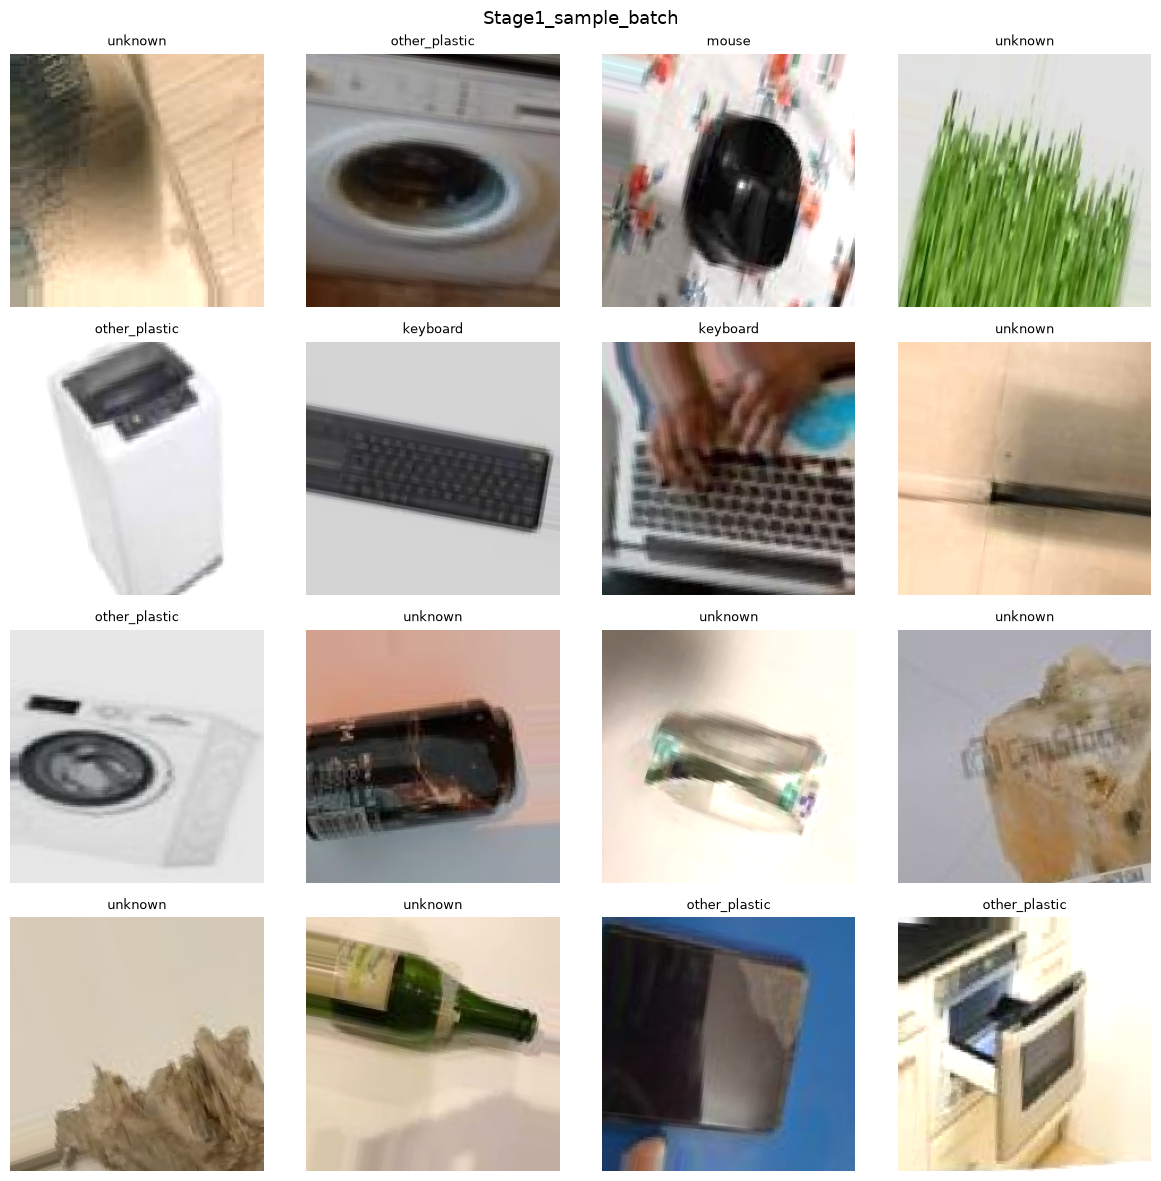

In [5]:
def show_batch(gen, class_names, title, n=16):
    imgs, labels = next(gen)
    imgs_disp = (imgs - imgs.min()) / (imgs.max() - imgs.min() + 1e-7)  # normalise for display
    fig, axes = plt.subplots(n//4, 4, figsize=(12, (n//4)*3))
    fig.suptitle(title, fontsize=13)
    for i, ax in enumerate(axes.flat):
        if i < len(imgs_disp):
            ax.imshow(imgs_disp[i])
            ax.set_title(class_names[labels[i].argmax()], fontsize=9)
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{title}.png", dpi=100)
    plt.show()

show_batch(s0_train, s0_classes, 'Stage0_sample_batch')
show_batch(s1_train, s1_classes, 'Stage1_sample_batch')

## Cell 6 — Model builder, callbacks, helpers

In [6]:
def build_model(num_classes, model_name='mobilenetv2'):
    """
    Transfer-learning classifier.

    Architecture:
      Input(224×224×3) → Pretrained base (frozen) → GlobalAveragePooling2D
      → Dropout(0.4) → Dense(num_classes, softmax)

    Returns (model, base_model) so we can unfreeze base layers in Phase 2
    without rebuilding the full model.
    """
    inp = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    kw  = dict(include_top=False, weights='imagenet', input_tensor=inp)

    base = {'mobilenetv2':   MobileNetV2,
            'efficientnetb0': EfficientNetB0,
            'mobilenetv3':    MobileNetV3Large}[model_name](**kw)
    base.trainable = False

    x   = layers.GlobalAveragePooling2D(name='gap')(base.output)
    x   = layers.Dropout(DROPOUT, name='dropout')(x)
    out = layers.Dense(num_classes, activation='softmax', name='predictions')(x)

    model = Model(inp, out, name=f"{model_name}_classifier")
    model.compile(optimizer=keras.optimizers.Adam(LR_HEAD),
                  loss='categorical_crossentropy', metrics=['accuracy'])

    trainable = sum(np.prod(v.shape) for v in model.trainable_variables)
    print(f"  {model_name}: {model.count_params():,} total, {trainable:,} trainable (head only)")
    return model, base


def enable_fine_tuning(model, base):
    """Phase 2: unfreeze the last FINE_TUNE_AT layers of base at a low LR."""
    base.trainable = True
    for layer in base.layers[:FINE_TUNE_AT]:
        layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(LR_FINE),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    unfrozen = sum(1 for l in base.layers if l.trainable)
    print(f"  Fine-tune: {unfrozen} base layers unfrozen at LR={LR_FINE}")


def make_callbacks(stage, model_name):
    path = str(OUTPUT_DIR / f"{stage}_{model_name}_best.keras")
    return [
        keras.callbacks.ModelCheckpoint(path, monitor='val_accuracy',
                                         save_best_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=5,
                                       restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                           patience=3, min_lr=1e-7, verbose=1),
    ]


def plot_history(hist_list, labels, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    offset = 0
    for h, lbl in zip(hist_list, labels):
        ep = range(offset, offset + len(h.epoch))
        axes[0].plot(ep, h.history['accuracy'],     label=f'{lbl} train')
        axes[0].plot(ep, h.history['val_accuracy'], label=f'{lbl} val', ls='--')
        axes[1].plot(ep, h.history['loss'],         label=f'{lbl} train')
        axes[1].plot(ep, h.history['val_loss'],     label=f'{lbl} val', ls='--')
        if offset > 0:
            axes[0].axvline(offset, color='grey', ls=':', alpha=0.6)
            axes[1].axvline(offset, color='grey', ls=':', alpha=0.6)
        offset += len(h.epoch)
    for ax, ylabel in zip(axes, ['Accuracy', 'Loss']):
        ax.set(title=f'{title} — {ylabel}', xlabel='Epoch', ylabel=ylabel)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{title}_curves.png", dpi=120)
    plt.show()


print("Helpers defined.")

Helpers defined.


## Cell 7 — Train Stage 0 (Material Sorter) — MobileNetV2

Stage 0 — Phase 1 (head only)


  mobilenetv2: 2,265,670 total, 7,686 trainable (head only)
Epoch 1/15


211/211 [==============================] - ETA: 0s - loss: 1.2091 - accuracy: 0.5361
Epoch 1: val_accuracy improved from -inf to 0.70562, saving model to models\stage0_mobilenetv2_best.keras
211/211 [==============================] - 187s 871ms/step - loss: 1.2091 - accuracy: 0.5361 - val_loss: 0.8165 - val_accuracy: 0.7056 - lr: 0.0010
Epoch 2/15
211/211 [==============================] - ETA: 0s - loss: 0.7989 - accuracy: 0.6883
Epoch 2: val_accuracy improved from 0.70562 to 0.71885, saving model to models\stage0_mobilenetv2_best.keras
211/211 [==============================] - 142s 676ms/step - loss: 0.7989 - accuracy: 0.6883 - val_loss: 0.8123 - val_accuracy: 0.7189 - lr: 0.0010
Epoch 3/15
211/211 [==============================] - ETA: 0s - loss: 0.7037 - accuracy: 0.7186
Epoch 3: val_accuracy improved from 0.71885 to 0.76847, saving model to models\stage0_mobilenetv2_best.kera

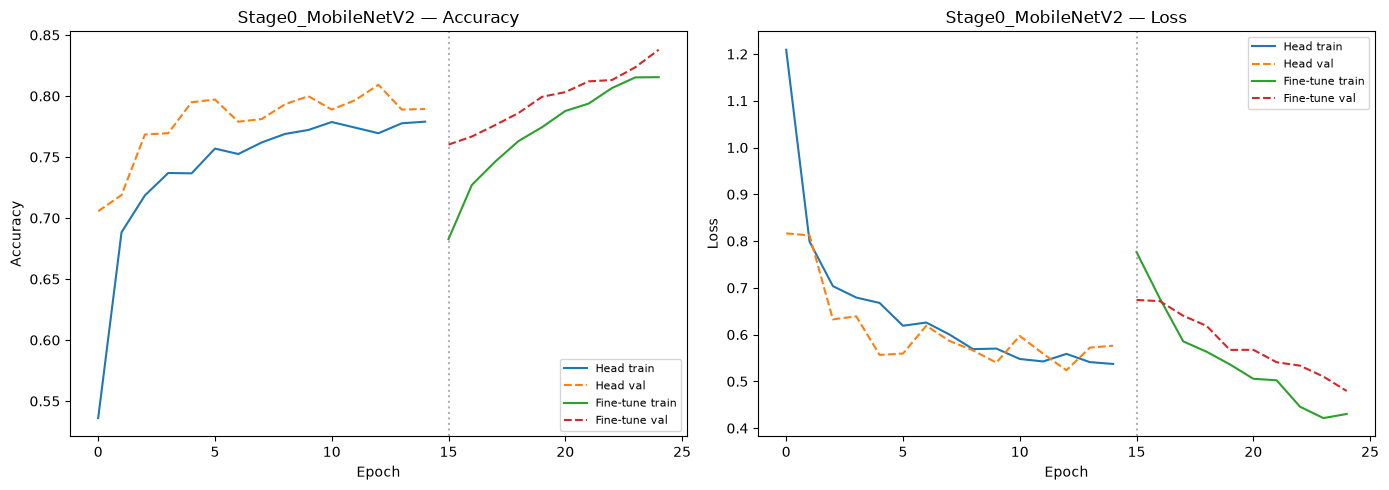

In [7]:
print("Stage 0 — Phase 1 (head only)")
s0_model, s0_base = build_model(len(s0_classes), 'mobilenetv2')

t0 = time.time()
h0_head = s0_model.fit(s0_train, epochs=EPOCHS_HEAD, validation_data=s0_val,
                        class_weight=s0_cw, callbacks=make_callbacks('stage0', 'mobilenetv2'))
t_head = time.time() - t0
print(f"Phase 1: {t_head/60:.1f} min")

print("\nStage 0 — Phase 2 (fine-tune)")
enable_fine_tuning(s0_model, s0_base)

t1 = time.time()
h0_fine = s0_model.fit(s0_train, epochs=EPOCHS_FINE, validation_data=s0_val,
                        class_weight=s0_cw, callbacks=make_callbacks('stage0', 'mobilenetv2'))
t_fine = time.time() - t1
print(f"Phase 2: {t_fine/60:.1f} min  |  Total: {(t_head+t_fine)/60:.1f} min")

# Save
s0_model.save(str(OUTPUT_DIR / 'stage0_model.keras'))
with open(OUTPUT_DIR / 'stage0_classes.json', 'w') as f:
    json.dump(s0_classes, f, indent=2)
print("Saved stage0_model.keras + stage0_classes.json")

plot_history([h0_head, h0_fine], ['Head', 'Fine-tune'], 'Stage0_MobileNetV2')

## Cell 8 — Stage 0 validation report

In [8]:
val_loss, val_acc = s0_model.evaluate(s0_val, verbose=0)
print(f"Val accuracy : {val_acc*100:.1f}%   Val loss: {val_loss:.4f}")

s0_val.reset()
probs  = s0_model.predict(s0_val, verbose=0)
y_pred = probs.argmax(axis=1)
y_true = s0_val.classes

print("\nPer-class report (validation):")
print(classification_report(y_true, y_pred, target_names=s0_classes, zero_division=0))

below = (probs.max(axis=1) < CONF_THRESHOLD).sum()
print(f"Below {CONF_THRESHOLD*100:.0f}% confidence (→ retake message): "
      f"{below}/{len(probs)} ({below/len(probs)*100:.1f}%)")

Val accuracy : 83.8%   Val loss: 0.4794

Per-class report (validation):
              precision    recall  f1-score   support

         PCB       0.70      0.95      0.81       145
     battery       0.80      0.94      0.87       127
glass_screen       0.59      0.81      0.68       117
       metal       0.77      0.84      0.80       144
     plastic       0.96      0.83      0.89       899
     unknown       0.80      0.79      0.80       382

    accuracy                           0.84      1814
   macro avg       0.77      0.86      0.81      1814
weighted avg       0.86      0.84      0.84      1814

Below 70% confidence (→ retake message): 326/1814 (18.0%)


## Cell 9 — Train Stage 1 (Item Classifier) — MobileNetV2

Stage 1 — Phase 1 (head only)
  mobilenetv2: 2,266,951 total, 8,967 trainable (head only)
Epoch 1/15
168/168 [==============================] - ETA: 0s - loss: 1.1563 - accuracy: 0.5468
Epoch 1: val_accuracy improved from -inf to 0.72919, saving model to models\stage1_mobilenetv2_best.keras
168/168 [==============================] - 155s 910ms/step - loss: 1.1563 - accuracy: 0.5468 - val_loss: 0.7224 - val_accuracy: 0.7292 - lr: 0.0010
Epoch 2/15
168/168 [==============================] - ETA: 0s - loss: 0.6441 - accuracy: 0.7148
Epoch 2: val_accuracy improved from 0.72919 to 0.74306, saving model to models\stage1_mobilenetv2_best.keras
168/168 [==============================] - 117s 695ms/step - loss: 0.6441 - accuracy: 0.7148 - val_loss: 0.6783 - val_accuracy: 0.7431 - lr: 0.0010
Epoch 3/15
168/168 [==============================] - ETA: 0s - loss: 0.5331 - accuracy: 0.7520
Epoch 3: val_accuracy improved from 0.74306 to 0.80515, saving model to models\stage1_mobilenetv2_best.keras
16

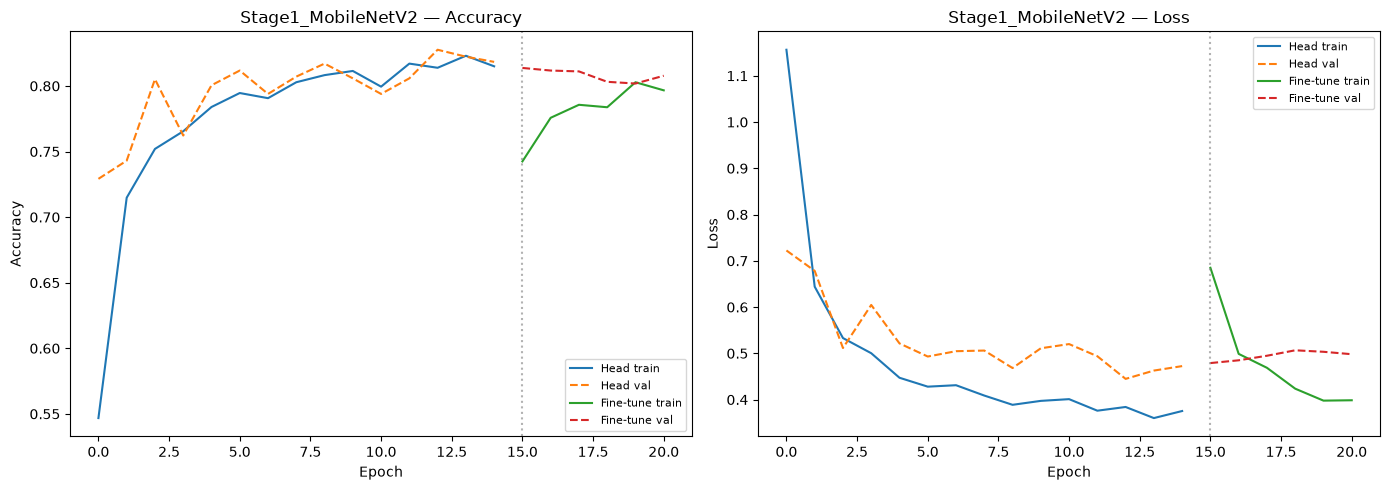


Stage 1 val accuracy: 81.4%
                precision    recall  f1-score   support

      keyboard       0.94      0.94      0.94       108
         mouse       0.83      0.81      0.82        80
 other_plastic       0.72      0.84      0.77       368
printer_casing       0.80      0.86      0.83        88
        remote       0.57      0.85      0.68        92
      tv_panel       0.80      0.84      0.82        88
       unknown       0.93      0.77      0.84       690

      accuracy                           0.81      1514
     macro avg       0.80      0.84      0.81      1514
  weighted avg       0.83      0.81      0.82      1514



In [9]:
print("Stage 1 — Phase 1 (head only)")
s1_model, s1_base = build_model(len(s1_classes), 'mobilenetv2')

t0 = time.time()
h1_head = s1_model.fit(s1_train, epochs=EPOCHS_HEAD, validation_data=s1_val,
                        class_weight=s1_cw, callbacks=make_callbacks('stage1', 'mobilenetv2'))
t_head = time.time() - t0

print("\nStage 1 — Phase 2 (fine-tune)")
enable_fine_tuning(s1_model, s1_base)

t1 = time.time()
h1_fine = s1_model.fit(s1_train, epochs=EPOCHS_FINE, validation_data=s1_val,
                        class_weight=s1_cw, callbacks=make_callbacks('stage1', 'mobilenetv2'))
t_fine = time.time() - t1
print(f"Total: {(t_head+t_fine)/60:.1f} min")

s1_model.save(str(OUTPUT_DIR / 'stage1_model.keras'))
with open(OUTPUT_DIR / 'stage1_classes.json', 'w') as f:
    json.dump(s1_classes, f, indent=2)
print("Saved stage1_model.keras + stage1_classes.json")

plot_history([h1_head, h1_fine], ['Head', 'Fine-tune'], 'Stage1_MobileNetV2')

_, acc = s1_model.evaluate(s1_val, verbose=0)
print(f"\nStage 1 val accuracy: {acc*100:.1f}%")
s1_val.reset()
probs = s1_model.predict(s1_val, verbose=0)
print(classification_report(s1_val.classes, probs.argmax(axis=1), target_names=s1_classes, zero_division=0))

## Cell 10 — Comparison models: EfficientNetB0 and MobileNetV3Large

Trained on Stage 0 only. Results go into `model_comparison.json` for `evaluation.ipynb`.

In [10]:
comparison = {}

# MobileNetV2 entry (already trained above)
s0_val.reset()
_, mnv2_acc = s0_model.evaluate(s0_val, verbose=0)
mnv2_size   = os.path.getsize(str(OUTPUT_DIR / 'stage0_model.keras')) / 1e6
dummy = np.random.rand(1, IMG_SIZE, IMG_SIZE, 3).astype('float32')
s0_model.predict(dummy, verbose=0)   # warm-up
t = time.time(); [s0_model.predict(dummy, verbose=0) for _ in range(50)]
comparison['MobileNetV2'] = {'val_accuracy': round(float(mnv2_acc), 4),
                              'model_size_mb': round(mnv2_size, 1),
                              'inference_ms': round((time.time()-t)/50*1000, 1)}

def train_comparison(model_name):
    tr, vl, _, _ = make_generators(STAGE0_ROOT, model_name)
    cw = get_class_weights(tr)
    m, base = build_model(len(s0_classes), model_name)
    t0 = time.time()
    m.fit(tr, epochs=EPOCHS_HEAD, validation_data=vl, class_weight=cw,
          callbacks=make_callbacks('stage0', model_name), verbose=0)
    enable_fine_tuning(m, base)
    m.fit(tr, epochs=EPOCHS_FINE, validation_data=vl, class_weight=cw,
          callbacks=make_callbacks('stage0', model_name), verbose=0)
    train_time = time.time() - t0
    path = str(OUTPUT_DIR / f'stage0_{model_name}.keras')
    m.save(path)
    _, acc = m.evaluate(vl, verbose=0)
    size_mb = os.path.getsize(path) / 1e6
    m.predict(dummy, verbose=0)   # warm-up
    t = time.time(); [m.predict(dummy, verbose=0) for _ in range(50)]
    inf_ms = (time.time()-t)/50*1000
    print(f"  {model_name}: acc={acc:.3f}  {train_time/60:.1f}min  {size_mb:.1f}MB  {inf_ms:.1f}ms")
    return {'val_accuracy': round(float(acc),4), 'train_time_s': round(train_time,1),
            'model_size_mb': round(size_mb,1), 'inference_ms': round(inf_ms,1)}

comparison['EfficientNetB0']   = train_comparison('efficientnetb0')
comparison['MobileNetV3Large'] = train_comparison('mobilenetv3')

with open(OUTPUT_DIR / 'model_comparison.json', 'w') as f:
    json.dump(comparison, f, indent=2)

print("\n── Comparison table ──")
print(f"{'Model':<20} {'Val Acc':>8} {'Size MB':>9} {'Inf ms':>8}")
print('-'*48)
for name, r in comparison.items():
    print(f"{name:<20} {r['val_accuracy']:>8.4f} {r['model_size_mb']:>9.1f} {r['inference_ms']:>8.1f}")

Found 6751 images belonging to 6 classes.
Found 1814 images belonging to 6 classes.
Found 1078 images belonging to 6 classes.
  [efficientnetb0] train=6751  val=1814  test=1078
   class indices: {'PCB': 0, 'battery': 1, 'glass_screen': 2, 'metal': 3, 'plastic': 4, 'unknown': 5}
   weights: {0: 1.87, 1: 2.05, 2: 2.24, 3: 2.03, 4: 0.36, 5: 0.8}
16705208/16705208 [==============================] - 3s 0us/step
  efficientnetb0: 4,057,257 total, 7,686 trainable (head only)

Epoch 1: val_accuracy improved from -inf to 0.77508, saving model to models\stage0_efficientnetb0_best.keras

Epoch 2: val_accuracy improved from 0.77508 to 0.80871, saving model to models\stage0_efficientnetb0_best.keras

Epoch 3: val_accuracy improved from 0.80871 to 0.82911, saving model to models\stage0_efficientnetb0_best.keras

Epoch 4: val_accuracy improved from 0.82911 to 0.83738, saving model to models\stage0_efficientnetb0_best.keras

Epoch 5: val_accuracy improved from 0.83738 to 0.84454, saving model to model

## Cell 11 — Grad-CAM preview

Sanity check: did the model focus on the object or the background?  
The reusable version is in `gradcam.py` (used by `app.py`).

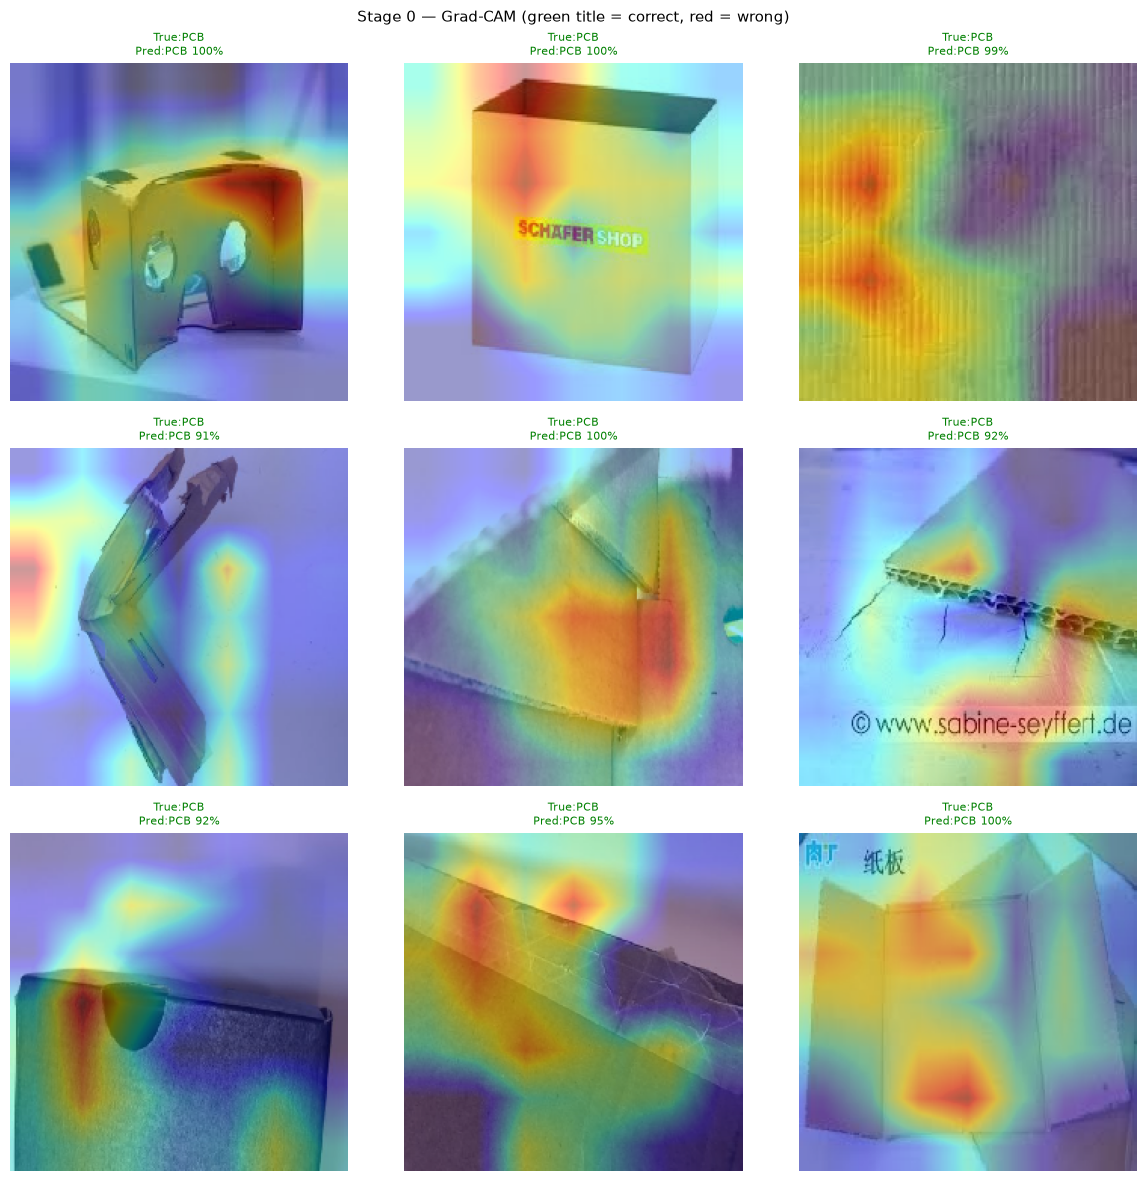

In [11]:
def quick_gradcam(model, img_array, class_idx, last_conv='out_relu'):
    """
    Grad-CAM heatmap for a single image.

    last_conv names:
      MobileNetV2    → 'out_relu'
      EfficientNetB0 → 'top_activation'
      MobileNetV3    → check model.summary() for the last Conv layer name
    """
    grad_model = Model(model.inputs,
                       [model.get_layer(last_conv).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_array, training=False)
        score = preds[:, class_idx]
    grads        = tape.gradient(score, conv_out)
    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))
    heatmap      = tf.squeeze(conv_out[0] @ pooled_grads[..., tf.newaxis])
    heatmap      = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def overlay_heatmap(img_uint8, heatmap):
    h, w  = img_uint8.shape[:2]
    heat  = cv2.resize(heatmap, (w, h))
    color = (cm.jet(heat)[:,:,:3] * 255).astype('uint8')
    return cv2.addWeighted(img_uint8, 0.6, color, 0.4, 0)


s0_val.reset()
batch_imgs, batch_labels = next(s0_val)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
fig.suptitle('Stage 0 — Grad-CAM (green title = correct, red = wrong)', fontsize=11)

for i, ax in enumerate(axes.flat):
    if i >= len(batch_imgs):
        ax.axis('off'); continue
    img   = batch_imgs[i:i+1]
    probs = s0_model.predict(img, verbose=0)[0]
    pred  = probs.argmax()
    true  = batch_labels[i].argmax()
    try:
        hm  = quick_gradcam(s0_model, img, pred)
        rgb = ((img[0]-img[0].min())/(img[0].max()-img[0].min())*255).astype('uint8')
        ax.imshow(overlay_heatmap(rgb, hm))
    except Exception as e:
        ax.imshow(((img[0]-img[0].min())/(img[0].max()-img[0].min())))
        print(f"Grad-CAM error {i}: {e}")
    ax.set_title(f"True:{s0_classes[true]}\nPred:{s0_classes[pred]} {probs[pred]*100:.0f}%",
                 fontsize=8, color='green' if pred==true else 'red')
    ax.axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'stage0_gradcam_preview.png', dpi=120)
plt.show()

## Cell 12 — Dataset collection guide

In [12]:
print("""
DATASET COLLECTION GUIDE
========================

Stage 0 — 7 classes                min images
  plastic        (casings, shells)     200–300
  metal          (chassis, frames)     150–200
  PCB            (bare + populated)    150–200
  glass_screen   (LCD, CRT)            100–150
  cable_wire     (USB, power, ribbon)  100–150
  battery        (Li-ion, NiMH, etc.)  100–150
  unknown        (hands, walls, cups)  150–200

Stage 1 — 8 classes                min images
  keyboard                             100–150
  mouse                                100–150
  charger_casing (phone + laptop)       80–120
  printer_casing (inkjet + laser)       80–120
  tv_panel       (CRT back, LCD back)   80–120
  remote         (TV, AC remotes)      100–150
  other_plastic  (anything else)        80–120
  unknown        (non-e-waste)         100–150

Split: 70% train / 15% val / 15% test
  Shuffle images randomly before splitting.
  Never look at the test set until evaluation.ipynb.

Separate evaluation set (for evaluation.ipynb):
  Photograph 20–30 images per class AFTER the training set,
  on a different phone, different lighting, different backgrounds.

Sources:
  Kaggle  — search 'e-waste images dataset'
  Roboflow — search 'e-waste'
  Your own photos (most valuable)
""")


DATASET COLLECTION GUIDE

Stage 0 — 7 classes                min images
  plastic        (casings, shells)     200–300
  metal          (chassis, frames)     150–200
  PCB            (bare + populated)    150–200
  glass_screen   (LCD, CRT)            100–150
  cable_wire     (USB, power, ribbon)  100–150
  battery        (Li-ion, NiMH, etc.)  100–150
  unknown        (hands, walls, cups)  150–200

Stage 1 — 8 classes                min images
  keyboard                             100–150
  mouse                                100–150
  charger_casing (phone + laptop)       80–120
  printer_casing (inkjet + laser)       80–120
  tv_panel       (CRT back, LCD back)   80–120
  remote         (TV, AC remotes)      100–150
  other_plastic  (anything else)        80–120
  unknown        (non-e-waste)         100–150

Split: 70% train / 15% val / 15% test
  Shuffle images randomly before splitting.
  Never look at the test set until evaluation.ipynb.

Separate evaluation set (for evaluatio

## Cell 13 — List saved files

In [13]:
print("Files in /content/reform_output/:")
for f in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {f.name:<45} {f.stat().st_size/1e6:.2f} MB")

Files in /content/reform_output/:
  model_comparison.json                         0.00 MB
  stage0_classes.json                           0.00 MB
  stage0_efficientnetb0.keras                   29.03 MB
  stage0_efficientnetb0_best.keras              29.03 MB
  stage0_gradcam_preview.png                    1.37 MB
  stage0_mobilenetv2_best.keras                 21.88 MB
  Stage0_MobileNetV2_curves.png                 0.09 MB
  stage0_mobilenetv3.keras                      20.46 MB
  stage0_mobilenetv3_best.keras                 20.46 MB
  stage0_model.keras                            21.88 MB
  Stage0_sample_batch.png                       0.90 MB
  stage1_classes.json                           0.00 MB
  stage1_mobilenetv2_best.keras                 21.90 MB
  Stage1_MobileNetV2_curves.png                 0.09 MB
  stage1_model.keras                            21.90 MB
  Stage1_sample_batch.png                       0.92 MB


## Cell 14 — Download models to your local machine

This zips only the files you need locally (`*.keras` + `*.json`).  
Extract to `models\` on your machine.

In [14]:
# Save final outputs locally (no Colab download needed)
print("Files saved to G:\\clg\\ReForm\\models\\")
for f in sorted((Path('G:\\clg\\ReForm\\models')).iterdir() if (Path('G:\\clg\\ReForm\\models')).exists() else []):
    print(f"  {f.name}")

# Optional: zip the output for backup
zip_path = 'G:\\clg\\ReForm\\reform_models.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for f in OUTPUT_DIR.iterdir():
        if f.suffix in {'.keras', '.json'}:
            zf.write(str(f), arcname=f.name)
            print(f"  Added to zip: {f.name}")

print(f"\nBackup zip created: {zip_path}")

Files saved to models\
  model_comparison.json
  stage0_classes.json
  stage0_efficientnetb0.keras
  stage0_efficientnetb0_best.keras
  stage0_gradcam_preview.png
  stage0_mobilenetv2_best.keras
  Stage0_MobileNetV2_curves.png
  stage0_mobilenetv3.keras
  stage0_mobilenetv3_best.keras
  stage0_model.keras
  Stage0_sample_batch.png
  stage1_classes.json
  stage1_mobilenetv2_best.keras
  Stage1_MobileNetV2_curves.png
  stage1_model.keras
  Stage1_sample_batch.png
  Added to zip: model_comparison.json
  Added to zip: stage0_classes.json
  Added to zip: stage0_efficientnetb0.keras
  Added to zip: stage0_efficientnetb0_best.keras
  Added to zip: stage0_mobilenetv2_best.keras
  Added to zip: stage0_mobilenetv3.keras
  Added to zip: stage0_mobilenetv3_best.keras
  Added to zip: stage0_model.keras
  Added to zip: stage1_classes.json
  Added to zip: stage1_mobilenetv2_best.keras
  Added to zip: stage1_model.keras

Backup zip created: .\reform_models.zip
